# Time Series Analysis in Python: Fundamentals and Decomposition  
**Episode 1:** Introduction to Stochastic Processes and Classical Decomposition

In this first notebook we formally introduce the concept of a time series, distinguishing it from cross-sectional data, and see how to isolate the structural components of a temporal signal (Trend, Seasonality and Residual).

In [1]:
# Import core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

# Plot style configuration
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## Theory: What Is a Time Series?

Formally, a **time series** is a sample realization of a **stochastic process** indexed by time. 

Let $(\Omega, \mathcal{F}, P)$ be a probability space. A stochastic process is a family of random variables $\{X_t\}_{t \in T}$ defined on the same probability space, where $T$ is the set of time indices (typically $T = \mathbb{Z}$ or $T = \mathbb{N}$).

*   **Cross-Sectional Data:** Observations on different entities at the same point in time (e.g. the GDP of various countries in 2025).
*   **Time Series:** Observations on the *same* entity at successive points in time (e.g. Italy's GDP from 1960 to 2025).

Unlike cross-sectional data, in time series the assumption of **independence** between observations almost always fails: $X_t$ is strongly correlated with its past values $X_{t-1}, X_{t-2}, \dots$ (autocorrelation).

## The Classical Decomposition Model

Many economic and environmental time series can be seen as the combination of three fundamental deterministic or stochastic components:

1.  **Trend ($m_t$):** The long-run component, reflecting structural growth or decline.
2.  **Seasonality ($s_t$):** Fixed periodic fluctuations (e.g. yearly, monthly, daily). The periodicity property holds: $s_{t} = s_{t-s}$.
3.  **Residual / Noise ($Y_t$):** The irregular stochastic component, which ideally represents unexplained random fluctuations.

The two classical decomposition frameworks are:
*   **Additive:** $X_t = m_t + s_t + Y_t$ (used when the seasonal amplitude is constant as the trend changes).
*   **Multiplicative:** $X_t = m_t \cdot s_t \cdot Y_t$ (used when the seasonal amplitude grows proportionally with the trend).

In [2]:
# Load a classic historical dataset: monthly airline passengers (1949-1960)
# This dataset clearly shows both an increasing trend and multiplicative seasonality.
data = sm.datasets.get_rdataset('AirPassengers').data

# The dataset has a 'time' column (decimal format e.g. 1949.0, 1949.083) and a 'value' column
# Build a proper time index in pandas
dates = pd.date_range(start='1949-01-01', periods=len(data), freq='ME')
ts = pd.Series(data['value'].values, index=dates, name='AirPassengers')

print(ts.head())

1949-01-31    112
1949-02-28    118
1949-03-31    132
1949-04-30    129
1949-05-31    121
Freq: ME, Name: AirPassengers, dtype: int64


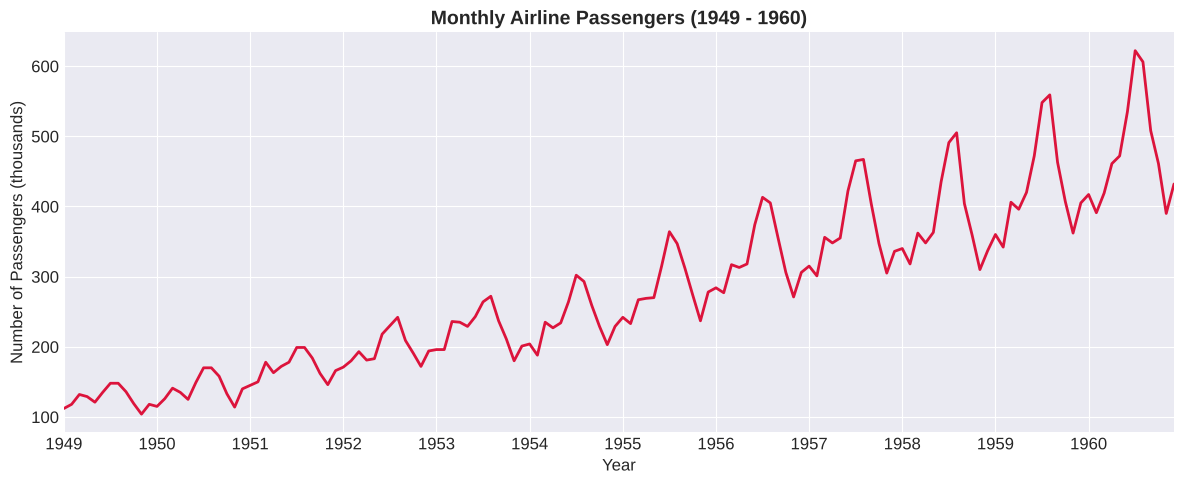

In [3]:
import matplotlib.pyplot as plt

# Plot the raw time series with explicit yearly labels
fig, ax = plt.subplots(figsize=(12, 5))
ts.plot(ax=ax, color='crimson', linewidth=2)

# Explicitly select every January as a tick position (one per year)
january_dates = ts.index[ts.index.month == 1]
ax.set_xticks(january_dates)

# Set labels formatted with the year only (e.g. 1949, 1950...)
ax.set_xticklabels([d.strftime('%Y') for d in january_dates], rotation=0, ha='center')

ax.set_title('Monthly Airline Passengers (1949 - 1960)', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Passengers (thousands)')
ax.set_xlabel('Year')

plt.tight_layout()
plt.show()

## Trend Extraction with Moving Averages

To estimate the trend $m_t$, the simplest and most intuitive method is to apply a **centered moving average filter** of order $L$. 

If the seasonal period is $s$ (e.g. $s = 12$ for monthly data), the symmetric moving average of order $s$ is defined as:
$$\hat{m}_t = \frac{1}{s} \left( \frac{1}{2}X_{t - s/2} + X_{t - s/2 + 1} + \dots + X_{t + s/2 - 1} + \frac{1}{2}X_{t + s/2} \right)$$
This filter removes (or strongly attenuates) the seasonal component.

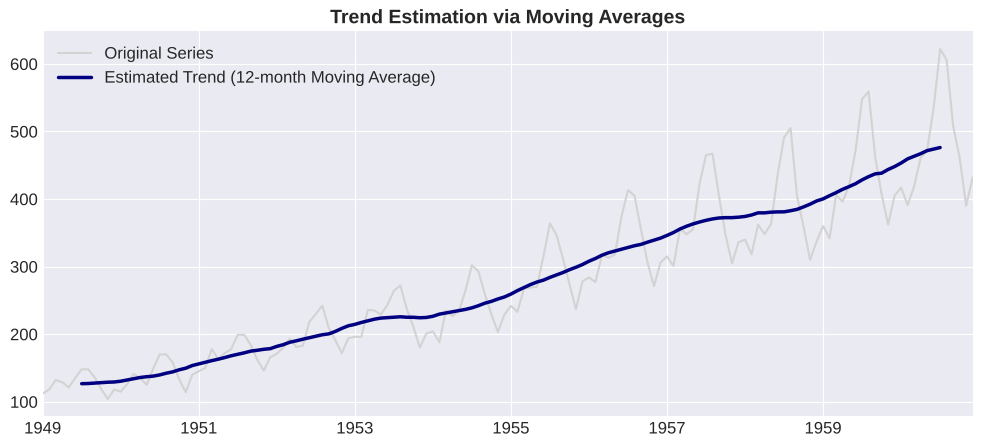

In [4]:
# Compute a 12-month moving average to estimate the trend
# center=True aligns the moving average to the central period
trend_estimate = ts.rolling(window=12, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ts.plot(ax=ax, label='Original Series', color='lightgray', linewidth=1.5)
trend_estimate.plot(ax=ax, label='Estimated Trend (12-month Moving Average)', color='navy', linewidth=2.5)
ax.set_title('Trend Estimation via Moving Averages', fontsize=14, fontweight='bold')
ax.legend()
plt.show()

## Automatic Decomposition with `statsmodels`

Now we use the `seasonal_decompose` function from `statsmodels` to fully separate the three components (Trend and Cycle are kept together) using a **multiplicative** model (since the amplitude of the seasonal oscillations grows as the level of the series increases).

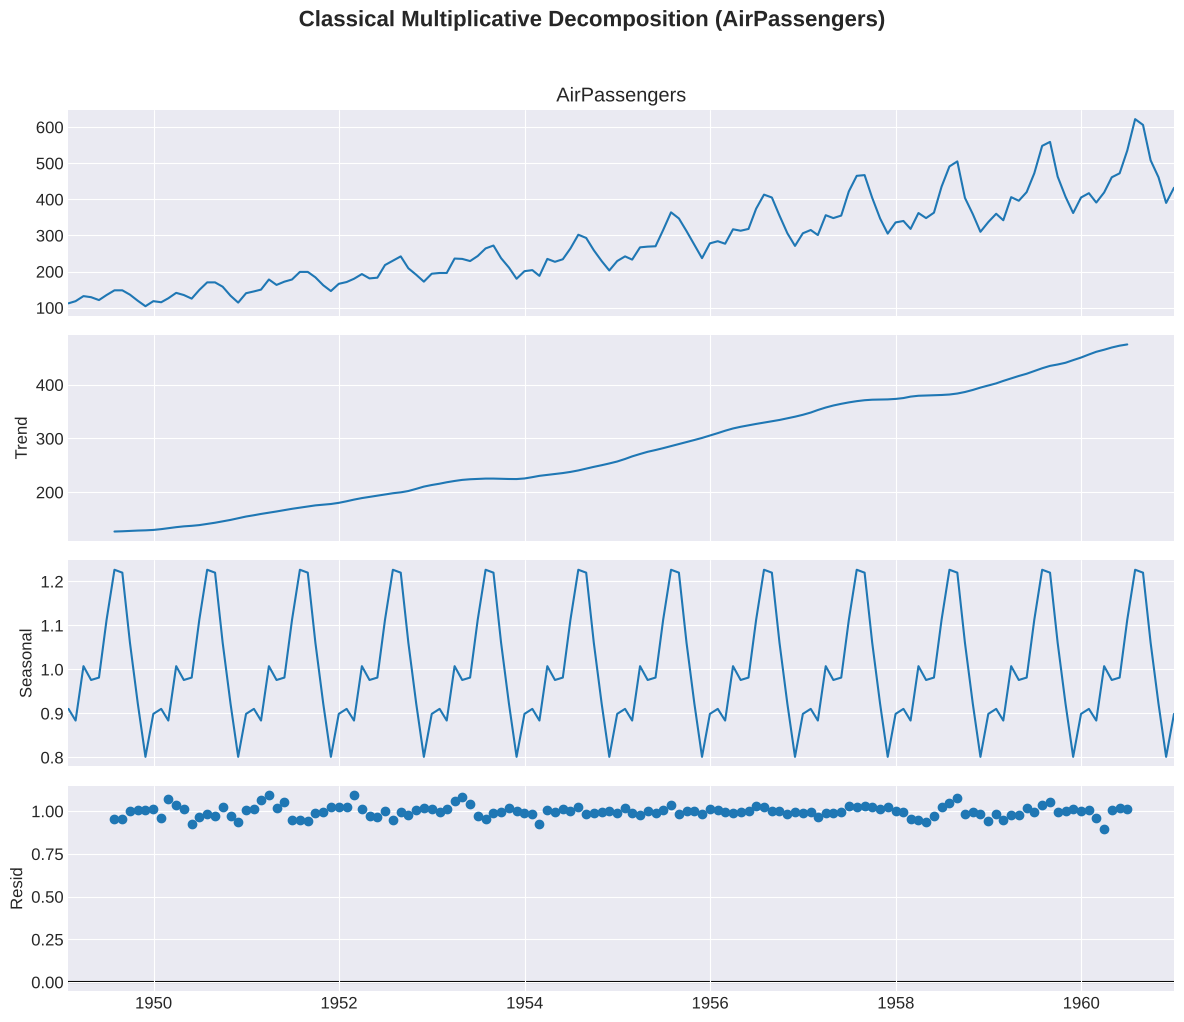

In [5]:
# Run the classical multiplicative decomposition
decomposition = seasonal_decompose(ts, model='multiplicative', period=12)

# Extract the components
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# Plot all components in a single multi-panel figure
fig = decomposition.plot()
fig.set_size_inches(12, 10)
fig.suptitle('Classical Multiplicative Decomposition (AirPassengers)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()